<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/mathematical_biology/mathbio_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Mathematical Biology* — `mathbio_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# MathBio Ch 1 Figures — Colab Notebook
**Mathematical Biology · Chapter 1: Population Dynamics**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch01/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Logistic growth: $N(t)$, phase line, bifurcation | §1.1 |
| fig02 | Delay DDE: oscillations, stability boundary, period $4T$ | §1.2 |
| fig03 | Lotka-Volterra phase plane + SIR epidemic | §1.4–1.5 |
| fig04 | Michaelis-Menten kinetics + FitzHugh-Nagumo | §1.6–1.7 |
| fig05 | SIR: final size, herd immunity, dynamics | §1.5 |

---
## fig01 · Logistic Growth (§1.1)

**Left**: $N(t)$ — S-shaped curves, all converging to $K$. **Centre**: Phase line $\dot N=f(N)$ — filled/open dots = stable/unstable FPs, arrows show flow. **Right**: Bifurcation diagram in $r$ — transcritical bifurcation at $r=0$.

  saved -> figures/ch01/fig01_logistic.png


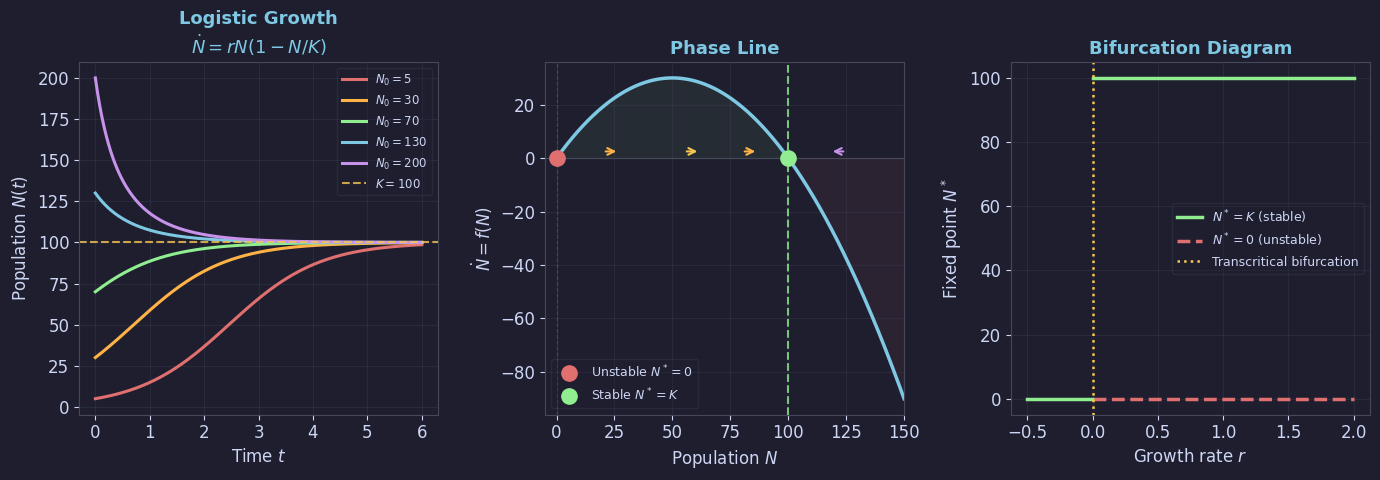

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Logistic Growth (§1.1) ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
r, K = 1.2, 100
t = np.linspace(0, 6, 300)

ax = axes[0]
for N0, col in [(5,RED),(30,ORANGE),(70,GREEN),(130,BLUE),(200,PURPLE)]:
    N = K*N0*np.exp(r*t)/(K + N0*(np.exp(r*t)-1))
    ax.plot(t, N, color=col, lw=2.2, label=f'$N_0={N0}$')
ax.axhline(K, color=YELLOW, lw=1.5, ls='--', alpha=0.8, label=f'$K={K}$')
ax.set_xlabel('Time $t$'); ax.set_ylabel('Population $N(t)$')
ax.set_title(r'Logistic Growth'+'\n'+r'$\dot N = rN(1-N/K)$', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)

N_arr = np.linspace(0, 1.5*K, 400); fN = r*N_arr*(1-N_arr/K)
ax2 = axes[1]
ax2.plot(N_arr, fN, color=BLUE, lw=2.5)
ax2.axhline(0, color=EDGE, lw=0.8); ax2.axvline(0, color=EDGE, lw=0.8, ls='--')
ax2.axvline(K, color=GREEN, lw=1.5, ls='--', alpha=0.8)
ax2.plot([0],[0],'o',color=RED,ms=11,zorder=5,label='Unstable $N^*=0$')
ax2.plot([K],[0],'o',color=GREEN,ms=11,zorder=5,label='Stable $N^*=K$')
for N0v,col in [(20,ORANGE),(55,YELLOW),(80,ORANGE),(125,PURPLE)]:
    fv=r*N0v*(1-N0v/K); dx=np.sign(fv)*7
    ax2.annotate('',xy=(N0v+dx,2.5),xytext=(N0v,2.5),
                arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=12))
ax2.fill_between(N_arr[(N_arr>0)&(N_arr<K)],0,fN[(N_arr>0)&(N_arr<K)],color=GREEN,alpha=0.07)
ax2.fill_between(N_arr[N_arr>K],0,fN[N_arr>K],color=RED,alpha=0.07)
ax2.set_xlabel('Population $N$'); ax2.set_ylabel(r'$\dot N = f(N)$')
ax2.set_title('Phase Line', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True); ax2.set_xlim(-5,1.5*K)

r_arr = np.linspace(-0.5, 2.0, 300)
ax3 = axes[2]
ax3.plot(r_arr[r_arr>0], K*np.ones(sum(r_arr>0)), color=GREEN, lw=2.5, label='$N^*=K$ (stable)')
ax3.plot(r_arr[r_arr>0], np.zeros(sum(r_arr>0)), color=RED, lw=2.5, ls='--', label='$N^*=0$ (unstable)')
ax3.plot(r_arr[r_arr<=0], np.zeros(sum(r_arr<=0)), color=GREEN, lw=2.5)
ax3.axvline(0, color=YELLOW, lw=1.8, ls=':', label='Transcritical bifurcation')
ax3.set_xlabel('Growth rate $r$'); ax3.set_ylabel('Fixed point $N^*$')
ax3.set_title('Bifurcation Diagram', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig01_logistic.png', fig)


---
## fig02 · Delay Logistic DDE (§1.2)

**Left**: Solutions for $rT<\pi/2$, $=\pi/2$, $>\pi/2$ — stable, marginal, oscillatory. **Centre**: Stability boundary at $rT_c=\pi/2$. **Right**: Period $\approx 4T$ for various delays.

  saved -> figures/ch01/fig02_delay.png


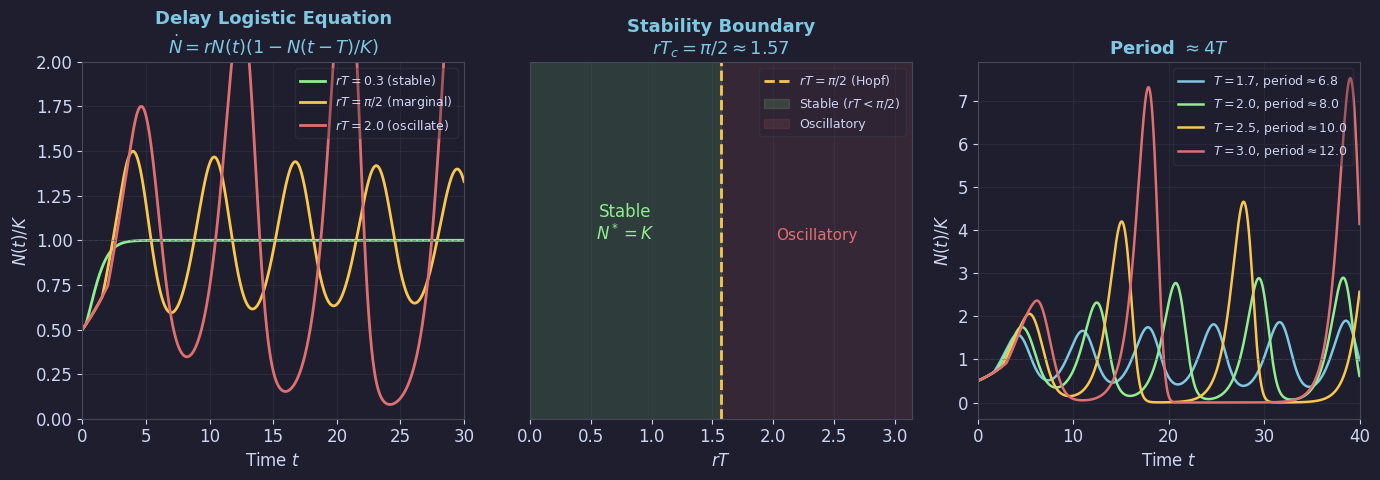

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Delay Logistic DDE (§1.2) ──────────────────────────────────────
def dde_logistic(T_delay, r_d=1.0, K_d=1.0, t_end=30, dt=0.01):
    n_steps = int(t_end/dt)
    n_delay = max(1, int(T_delay/dt))
    N = np.ones(n_steps + n_delay + 2)*K_d*0.8
    N[n_delay] = K_d*0.5
    for i in range(n_delay, n_steps+n_delay):
        N[i+1] = N[i] + dt*r_d*N[i]*(1 - N[i-n_delay]/K_d)
    return np.linspace(0, t_end, n_steps+1), N[n_delay:n_delay+n_steps+1]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
ax = axes[0]
for T_d,col,lab in [(0.3,GREEN,r'$rT=0.3$ (stable)'),
                     (1.57,YELLOW,r'$rT=\pi/2$ (marginal)'),
                     (2.0,RED,r'$rT=2.0$ (oscillate)')]:
    t_d,N_d=dde_logistic(T_d); ax.plot(t_d,N_d,color=col,lw=2.0,label=lab)
ax.axhline(1.0,color=EDGE,lw=0.8,ls='--',alpha=0.5)
ax.set_xlabel('Time $t$'); ax.set_ylabel('$N(t)/K$')
ax.set_title('Delay Logistic Equation\n'+r'$\dot N=rN(t)(1-N(t-T)/K)$', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True); ax.set_xlim(0,30); ax.set_ylim(0,2.0)

ax2 = axes[1]
ax2.axvline(np.pi/2,color=YELLOW,lw=2.0,ls='--',label=r'$rT=\pi/2$ (Hopf)')
ax2.fill_between([0,np.pi/2],[0,0],[1,1],color=GREEN,alpha=0.15,label=r'Stable ($rT<\pi/2$)')
ax2.fill_between([np.pi/2,np.pi],[0,0],[1,1],color=RED,alpha=0.12,label=r'Oscillatory')
ax2.text(np.pi/4,0.5,'Stable\n$N^*=K$',ha='center',color=GREEN,fontsize=12)
ax2.text(np.pi*3/4,0.5,'Oscillatory',ha='center',color=RED,fontsize=11)
ax2.set_xlabel('$rT$'); ax2.set_yticks([])
ax2.set_title('Stability Boundary\n'+r'$rT_c=\pi/2\approx1.57$', color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True,axis='x')
ax2.set_xlim(0,np.pi); ax2.set_ylim(0,1)

ax3 = axes[2]
for T_d,col,lab in [(1.7,BLUE,'$T=1.7$'),(2.0,GREEN,'$T=2.0$'),
                     (2.5,YELLOW,'$T=2.5$'),(3.0,RED,'$T=3.0$')]:
    t_d,N_d=dde_logistic(T_d,t_end=40)
    ax3.plot(t_d,N_d,color=col,lw=1.8,label=f'$T={T_d}$, period$\\approx{4*T_d:.1f}$')
ax3.axhline(1.0,color=EDGE,lw=0.8,ls='--',alpha=0.4)
ax3.set_xlabel('Time $t$'); ax3.set_ylabel('$N(t)/K$')
ax3.set_title('Period $\\approx 4T$', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True); ax3.set_xlim(0,40)
plt.tight_layout(pad=1.2)
save('fig02_delay.png', fig)


---
## fig03 · Lotka-Volterra & SIR (§1.4–1.5)

**Left**: Phase plane — closed orbits around interior FP $(d/c,\ a/b)$. **Centre**: Predator-prey time series. **Right**: SIR epidemic curves for three values of $R_0$.

  saved -> figures/ch01/fig03_lv_sir.png


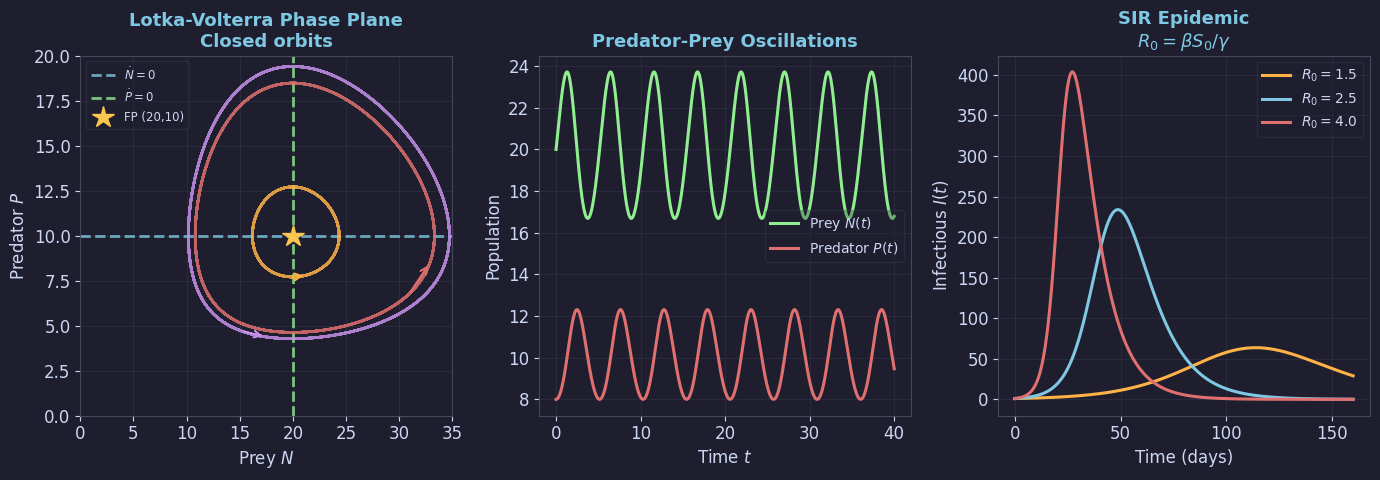

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Lotka-Volterra + SIR (§1.4-1.5) ────────────────────────────────
a,b,c,d = 1.0,0.1,0.075,1.5
def lv(t,y): return [a*y[0]-b*y[0]*y[1], c*y[0]*y[1]-d*y[1]]
def sir(t,y,beta=0.3,gamma=0.1,N=1000):
    S,I,R=y; return [-beta*S*I/N, beta*S*I/N-gamma*I, gamma*I]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
ax=axes[0]
ax.axhline(a/b,color=BLUE,lw=2.0,ls='--',label=r'$\dot N=0$',alpha=0.8)
ax.axvline(d/c,color=GREEN,lw=2.0,ls='--',label=r'$\dot P=0$',alpha=0.8)
ax.plot([d/c],[a/b],'*',color=YELLOW,ms=16,zorder=5,label=f'FP ({d/c:.0f},{a/b:.0f})')
for N0i,P0i,col in [(25,5,RED),(18,8,ORANGE),(12,6,PURPLE)]:
    sol=solve_ivp(lv,[0,50],[N0i,P0i],max_step=0.05,dense_output=True)
    tr=sol.sol(np.linspace(0,50,2000))
    ax.plot(tr[0],tr[1],color=col,lw=1.8,alpha=0.85)
    ax.annotate('',xy=(tr[0][30],tr[1][30]),xytext=(tr[0][20],tr[1][20]),
               arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=12))
ax.set_xlabel('Prey $N$'); ax.set_ylabel('Predator $P$')
ax.set_title('Lotka-Volterra Phase Plane\nClosed orbits', color=BLUE)
ax.legend(fontsize=8.5,labelcolor=FG); ax.grid(True)
ax.set_xlim(0,35); ax.set_ylim(0,20)

ax2=axes[1]
sol2=solve_ivp(lv,[0,40],[20,8],max_step=0.05,dense_output=True)
t2=np.linspace(0,40,1000); tr2=sol2.sol(t2)
ax2.plot(t2,tr2[0],color=GREEN,lw=2.2,label='Prey $N(t)$')
ax2.plot(t2,tr2[1],color=RED,lw=2.2,label='Predator $P(t)$')
ax2.set_xlabel('Time $t$'); ax2.set_ylabel('Population')
ax2.set_title('Predator-Prey Oscillations', color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True)

ax3=axes[2]
for R0v,col,lab in [(1.5,ORANGE,'$R_0=1.5$'),(2.5,BLUE,'$R_0=2.5$'),(4.0,RED,'$R_0=4.0$')]:
    sol3=solve_ivp(sir,[0,160],[999,1,0],args=(R0v*0.1,0.1,1000),
                   max_step=0.5,dense_output=True)
    tr3=sol3.sol(np.linspace(0,160,1000))
    ax3.plot(np.linspace(0,160,1000),tr3[1],color=col,lw=2.2,label=lab)
ax3.set_xlabel('Time (days)'); ax3.set_ylabel('Infectious $I(t)$')
ax3.set_title('SIR Epidemic\n'+r'$R_0=\beta S_0/\gamma$', color=BLUE)
ax3.legend(fontsize=10,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig03_lv_sir.png', fig)


---
## fig04 · Michaelis-Menten & FitzHugh-Nagumo (§1.6–1.7)

**Left**: MM rate curve — hyperbolic saturation, $K_M$ = half-saturation. **Centre**: QSSA accuracy vs full ODE. **Right**: FHN phase plane — cubic $v$-nullcline, linear $w$-nullcline, excitable/limit-cycle orbits.

  saved -> figures/ch01/fig04_mm_fhn.png


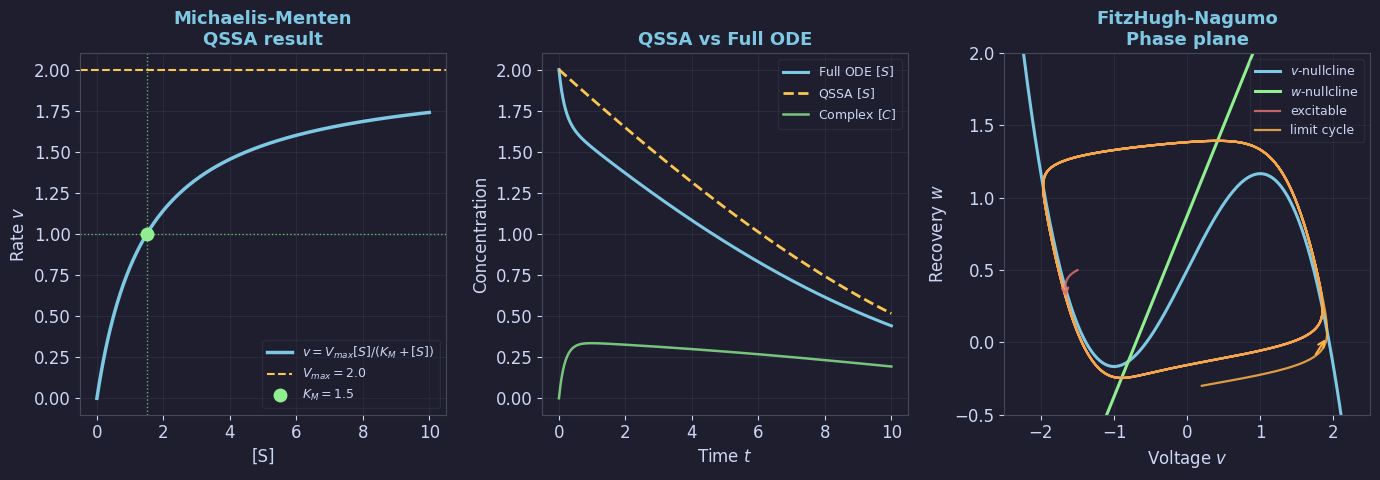

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: Michaelis-Menten + FitzHugh-Nagumo (§1.6-1.7) ──────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
S=np.linspace(0,10,300); Vmax,Km=2.0,1.5
ax=axes[0]
ax.plot(S,Vmax*S/(Km+S),color=BLUE,lw=2.5,label='$v=V_{max}[S]/(K_M+[S])$')
ax.axhline(Vmax,color=YELLOW,lw=1.5,ls='--',label=f'$V_{{max}}={Vmax}$')
ax.axhline(Vmax/2,color=GREEN,lw=1.0,ls=':',alpha=0.7)
ax.axvline(Km,color=GREEN,lw=1.0,ls=':',alpha=0.7)
ax.plot([Km],[Vmax/2],'o',color=GREEN,ms=9,zorder=5,label=f'$K_M={Km}$')
ax.set_xlabel('[S]'); ax.set_ylabel('Rate $v$')
ax.set_title('Michaelis-Menten\nQSSA result', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)

k1,km1,k2,E0=2.0,1.0,0.5,0.5; Km2=(km1+k2)/k1
def mm_full(t,y):
    S2,C,P=y; E=E0-C
    return [-k1*E*S2+km1*C, k1*E*S2-(km1+k2)*C, k2*C]
def mm_qssa(t,y): return [-(k2*E0*y[0])/(Km2+y[0])]
t_mm=np.linspace(0,10,500)
sf=solve_ivp(mm_full,[0,10],[2,0,0],max_step=0.02,dense_output=True)
sq=solve_ivp(mm_qssa,[0,10],[2],max_step=0.02,dense_output=True)
ax2=axes[1]
ax2.plot(t_mm,sf.sol(t_mm)[0],color=BLUE,lw=2.2,label='Full ODE $[S]$')
ax2.plot(t_mm,sq.sol(t_mm)[0],color=YELLOW,lw=2.0,ls='--',label='QSSA $[S]$')
ax2.plot(t_mm,sf.sol(t_mm)[1],color=GREEN,lw=1.8,alpha=0.8,label='Complex $[C]$')
ax2.set_xlabel('Time $t$'); ax2.set_ylabel('Concentration')
ax2.set_title('QSSA vs Full ODE', color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)

def fhn(t,y,I=0.5,a=0.7,b=0.8,tau=12.5):
    v,w=y; return [v-v**3/3-w+I,(v+a-b*w)/tau]
v_arr=np.linspace(-2.5,2.5,300)
ax3=axes[2]
ax3.plot(v_arr,v_arr-v_arr**3/3+0.5,color=BLUE,lw=2.2,label='$v$-nullcline')
ax3.plot(v_arr,(v_arr+0.7)/0.8,color=GREEN,lw=2.2,label='$w$-nullcline')
for v0,w0,col,lab in [(-1.5,0.5,RED,'excitable'),(0.2,-0.3,ORANGE,'limit cycle')]:
    sf2=solve_ivp(fhn,[0,100],[v0,w0],max_step=0.05,dense_output=True)
    tr=sf2.sol(np.linspace(0,100,3000))
    ax3.plot(tr[0],tr[1],color=col,lw=1.6,alpha=0.85,label=lab)
    ax3.annotate('',xy=(tr[0][60],tr[1][60]),xytext=(tr[0][40],tr[1][40]),
               arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=11))
ax3.set_xlabel('Voltage $v$'); ax3.set_ylabel('Recovery $w$')
ax3.set_title('FitzHugh-Nagumo\nPhase plane', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True)
ax3.set_xlim(-2.5,2.5); ax3.set_ylim(-0.5,2.0)
plt.tight_layout(pad=1.2)
save('fig04_mm_fhn.png', fig)


---
## fig05 · SIR Analysis (§1.5)

**Left**: Final epidemic size $R_\infty/N$ vs $R_0$ — threshold at $R_0=1$. **Centre**: Herd immunity threshold $p_v=1-1/R_0$ for real diseases. **Right**: SIR time series with $S$, $I$, $R$.

  saved -> figures/ch01/fig05_sir_analysis.png


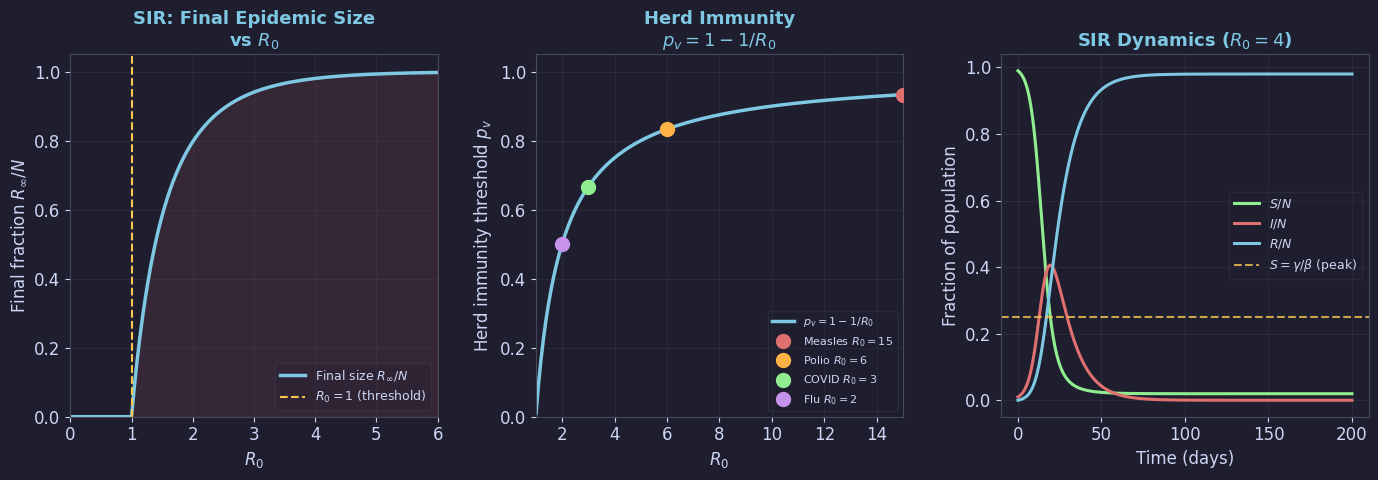

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: SIR Analysis (§1.5) ────────────────────────────────────────────
def sir(t,y,beta=0.3,gamma=0.1,N=1000):
    S,I,R=y; return [-beta*S*I/N, beta*S*I/N-gamma*I, gamma*I]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
R0_arr=np.linspace(0.01,6,400)
R_inf=np.array([0.0 if R0v<=1 else
                fsolve(lambda x:x-1+np.exp(-R0v*x),0.8)[0]
                for R0v in R0_arr])
ax=axes[0]
ax.plot(R0_arr,R_inf,color=BLUE,lw=2.5,label='Final size $R_\\infty/N$')
ax.axvline(1.0,color=YELLOW,lw=1.5,ls='--',label='$R_0=1$ (threshold)')
ax.fill_between(R0_arr[R0_arr>1],0,R_inf[R0_arr>1],color=RED,alpha=0.12)
ax.set_xlabel('$R_0$'); ax.set_ylabel('Final fraction $R_\\infty/N$')
ax.set_title('SIR: Final Epidemic Size\nvs $R_0$', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)
ax.set_xlim(0,6); ax.set_ylim(0,1.05)

ax2=axes[1]
R0_h=np.linspace(1.01,15,300)
ax2.plot(R0_h,1-1/R0_h,color=BLUE,lw=2.5,label='$p_v=1-1/R_0$')
for name,R0d,col in [('Measles $R_0=15$',15,RED),('Polio $R_0=6$',6,ORANGE),
                      ('COVID $R_0=3$',3,GREEN),('Flu $R_0=2$',2,PURPLE)]:
    ax2.plot([R0d],[1-1/R0d],'o',ms=10,color=col,zorder=5,label=name)
ax2.set_xlabel('$R_0$'); ax2.set_ylabel('Herd immunity threshold $p_v$')
ax2.set_title('Herd Immunity\n$p_v=1-1/R_0$', color=BLUE)
ax2.legend(fontsize=8,labelcolor=FG); ax2.grid(True)
ax2.set_xlim(1,15); ax2.set_ylim(0,1.05)

sol_sir=solve_ivp(sir,[0,200],[990,10,0],args=(0.4,0.1,1000),
                  max_step=0.5,dense_output=True)
t_s=np.linspace(0,200,1000); tr_s=sol_sir.sol(t_s)
ax3=axes[2]
ax3.plot(t_s,tr_s[0]/1000,color=GREEN,lw=2.2,label='$S/N$')
ax3.plot(t_s,tr_s[1]/1000,color=RED,lw=2.2,label='$I/N$')
ax3.plot(t_s,tr_s[2]/1000,color=BLUE,lw=2.2,label='$R/N$')
ax3.axhline(0.1/0.4,color=YELLOW,lw=1.5,ls='--',alpha=0.8,label='$S=\\gamma/\\beta$ (peak)')
ax3.set_xlabel('Time (days)'); ax3.set_ylabel('Fraction of population')
ax3.set_title('SIR Dynamics ($R_0=4$)', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig05_sir_analysis.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch01'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'mathbio_ch01_figures.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_logistic.png  (180 KB)
  fig02_delay.png  (268 KB)
  fig03_lv_sir.png  (248 KB)
  fig04_mm_fhn.png  (206 KB)
  fig05_sir_analysis.png  (166 KB)
Zip: mathbio_ch01_figures.zip  (1023 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>